In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import warnings
warnings.filterwarnings('ignore')

import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from load_everything import *
from harness import *
import pickle
from TimeseriesGenerator import TimeseriesGenerator
from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )

from f2_utils import *
import time_in_each_roi
import matplotlib.patches as patches
import time_in_each_roi
from sklearn.linear_model import MultiTaskLassoCV,LassoCV
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.model_selection import train_test_split

from keras.callbacks import ModelCheckpoint, EarlyStopping
from keras.layers import Dense, LSTM, Input, Lambda, Bidirectional, Conv1D
from keras.models import Model, Sequential
from keras.regularizers import l1_l2
from keras.utils import np_utils
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

from matplotlib.ticker import MaxNLocator

In [3]:
def save_pickle(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_pickle(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model

In [4]:
mouse = 'cm126'

In [6]:
prefix = '/mnt/staging/'
fetch_path = str(PREPARES / "modeling") + "/"
data_joint = load_model(fetch_path+mouse+'_data_joint.pickle')

In [7]:
seed = 8;SLICE_LEN = 40
model_weights_filename = f4_locker_root+'admin_cnn_main_weights_'+mouse+ '_len_'+str(SLICE_LEN)+'.hdf5'

timesteps=SLICE_LEN;num_in_features=500;num_out_features = 4
cnn_model = prepare_model('mean_absolute_error','mean_absolute_error',
                                        timesteps,
                                       num_in_features,
                                       num_out_features)
cnn_model.summary()


Instructions for updating:
If using Keras pass *_constraint arguments to layers.
Model: "model_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         (None, 40, 500)           0         
_________________________________________________________________
conv1d_1 (Conv1D)            (None, 40, 250)           2500250   
_________________________________________________________________
dense_1 (Dense)              (None, 40, 100)           25100     
_________________________________________________________________
dense_2 (Dense)              (None, 40, 4)             404       
Total params: 2,525,754
Trainable params: 2,525,754
Non-trainable params: 0
_________________________________________________________________


In [8]:
cnn_model = load_model(cnn_model, model_weights_filename) # load model is it has been trained

In [33]:
if mouse =='cm126':
    validation_flist = list(set(glob.glob(neural_root+"*"+mouse+"/[1-6]/H_*D*.mat"))-set(glob.glob(neural_root+"*"+mouse+"/[2]/H_*D*.mat")))
#     validation_flist = list(set(glob.glob(neural_root+"*"+mouse+"/[5]/H_*D*.mat"))-set(glob.glob(neural_root+"*"+mouse+"/[2]/H_*D*.mat")))

else:       
    validation_flist = list(set(glob.glob(neural_root+"*"+mouse+"/[1-6]/H_*D*.mat")))
validation_flist

['/home/wx2203/Weihao/data_locker/step_2/cm126/6/H_runD_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm126/1/H_runD_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm126/5/H_runD_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm126/3/H_runD_stim_1.mat']

cm126_6 runD   (10975, 500) (10975, 4)
rotf missing  cm126_1_runD
cm126_5 runD   (21950, 500) (21950, 4)
rotf missing  cm126_3_runD
(21950, 500) (21950, 4)


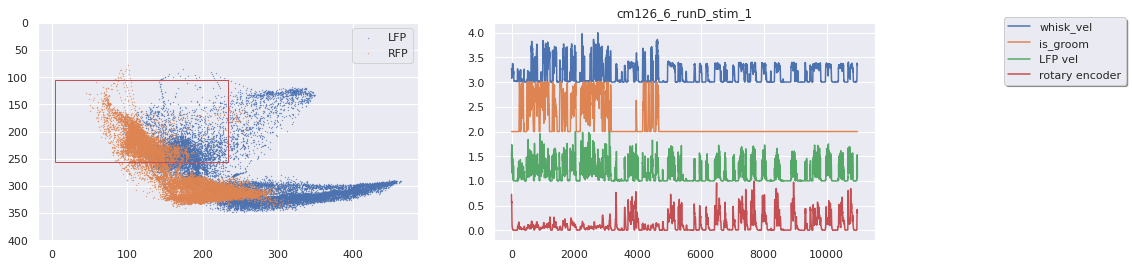

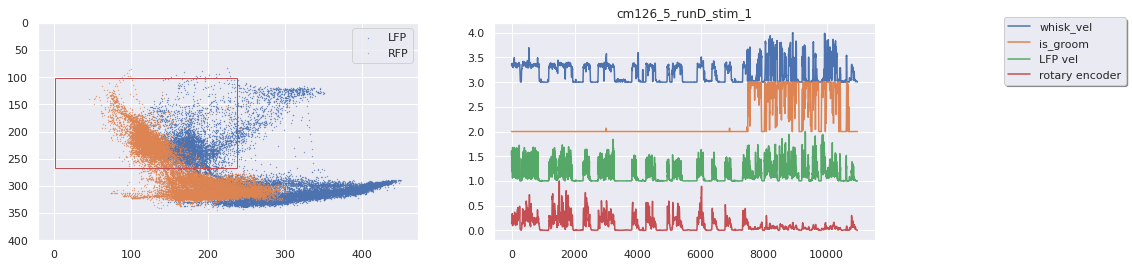

In [47]:
num_regions=500
H_cat ,all_bev_df_cat = load_everything_DLC(validation_flist,num_regions,
                                                    neural_root,whisk_dlc_root,groom_dlc_root,config_root=step_0_root)
H_cat[:,motor_region_ind==1] = 0
data_gen = TimeseriesGenerator(H_cat,all_bev_df_cat.values,
                              stride = 40,sampling_rate=1,
                              length=40,batch_size=1000000) 
X , Y = data_gen[0]

In [48]:
Y_hat = cnn_model.predict(X)
Y_hat_concat = Y_hat.reshape((Y_hat.shape[0]*Y_hat.shape[1],Y_hat.shape[-1]))
Y_concat = Y.reshape((Y_hat.shape[0]*Y_hat.shape[1],Y_hat.shape[-1]))

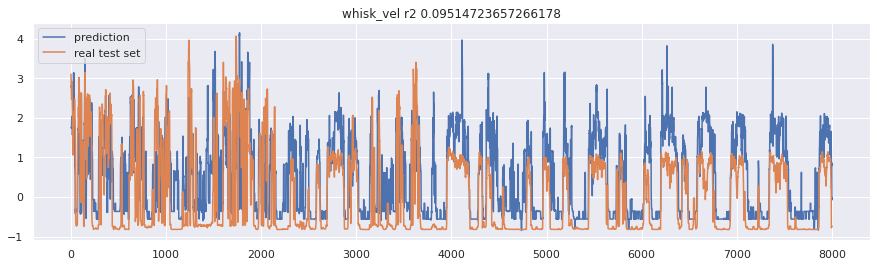

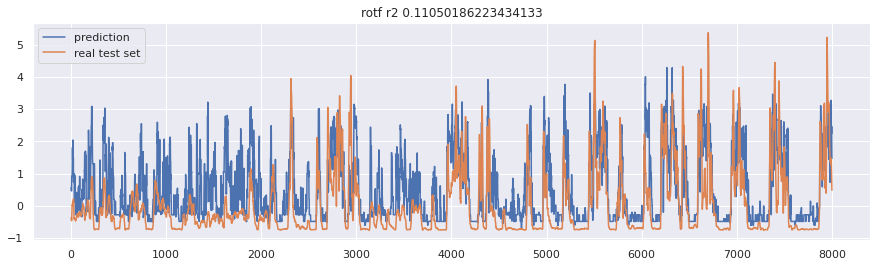

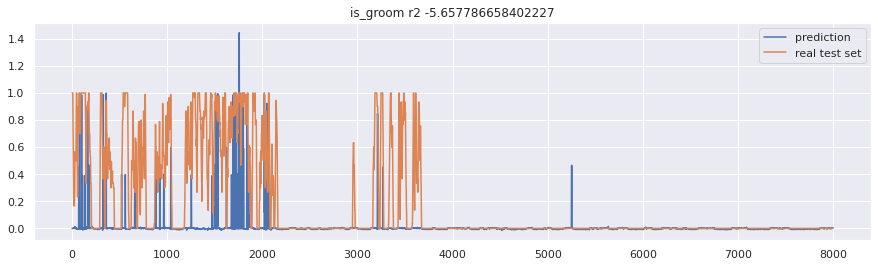

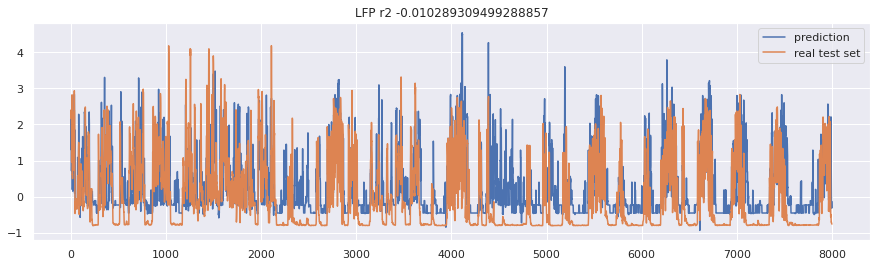

In [49]:
for i, name in enumerate(all_bev_df_cat.columns):
    plt.figure(figsize=(15,4))
    t_range = range(1000,9000)
    plt.plot(Y_hat_concat[t_range,i],label='prediction')
    plt.plot(Y_concat[t_range,i],label='real test set')
    r22 = r2_score(Y_hat_concat[:,i],Y_concat[:,i])
    plt.legend()
    plt.title(name+ ' r2 '+str(r22))

# linear model

In [37]:
f4_locker_root = '/scratch/users/wx2203/new_analysis_locker/f4/'
dict_models = load_pickle(f4_locker_root+'dict_linear_model_'+mouse)

In [43]:
print(H_cat.shape ,all_bev_df_cat.shape)

(21950, 500) (21950, 4)


In [42]:
f = scipy.io.loadmat('/home/wx2203/Weihao/analysis_locker/f2/'+mouse+'_motor_region_ind_0_0000001.mat')
motor_region_ind = np.squeeze(f['motor_region_ind'])

In [44]:
H_cat[:,motor_region_ind==1] = 0

In [45]:
all_bev_predict = pd.DataFrame(columns=all_bev_df_cat.columns)
for col in all_bev_df_cat.columns:
    Y_hat = dict_models[col].predict(H_cat)
    all_bev_predict[col] = Y_hat

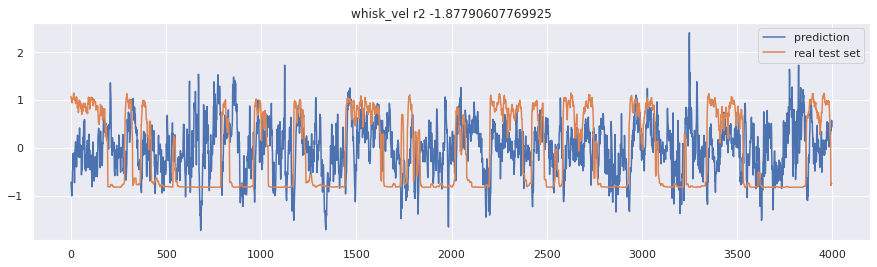

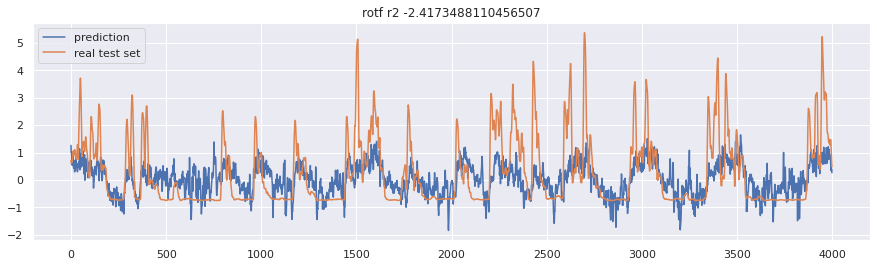

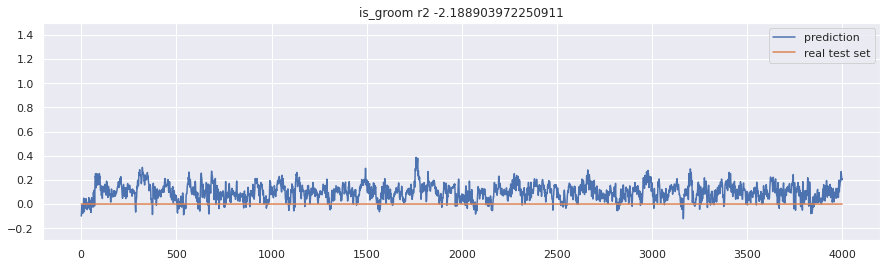

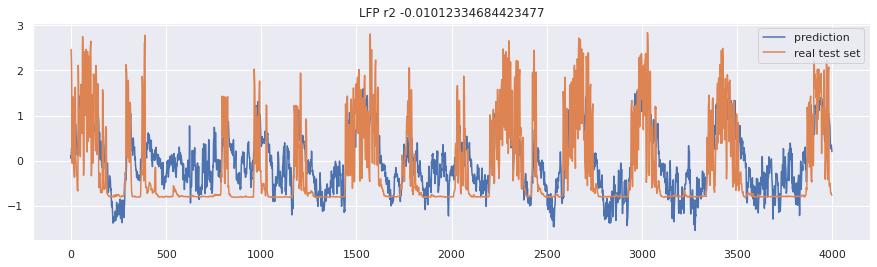

In [46]:
for i, name in enumerate(all_bev_df_cat.columns):
    plt.figure(figsize=(15,4))
    t_range = range(5000,9000)
    plt.plot(all_bev_predict.iloc[t_range,i].values,label='prediction')
    plt.plot(all_bev_df_cat.iloc[t_range,i].values,label='real test set')
    r22 = r2_score(all_bev_predict.iloc[t_range,i].values,all_bev_df_cat.iloc[t_range,i].values,)
    plt.legend()
    if name =='is_groom':
        plt.ylim([-0.3,1.5])
    plt.title(name+ ' r2 '+str(r22))

In [44]:
Y_hat = cnn_model.predict(X)
Y_hat_concat = Y_hat.reshape((Y_hat.shape[0]*Y_hat.shape[1],Y_hat.shape[-1]))
Y_concat = Y.reshape((Y_hat.shape[0]*Y_hat.shape[1],Y_hat.shape[-1]))

In [45]:
Y_hat_concat.shape

(43880, 5)

In [46]:
data_joint.iloc[:,500:].columns

Index(['whisk_vel', 'face_pc', 'rotf', 'is_groom', 'LFP'], dtype='object')

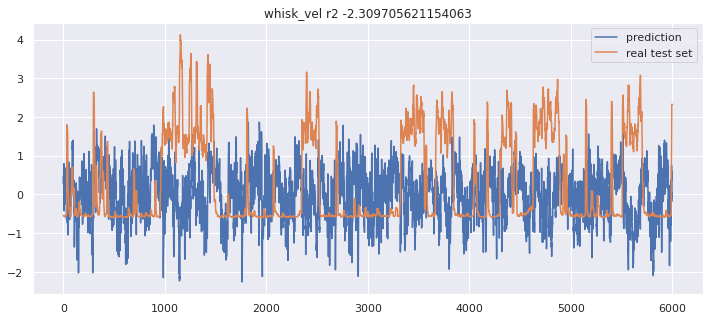

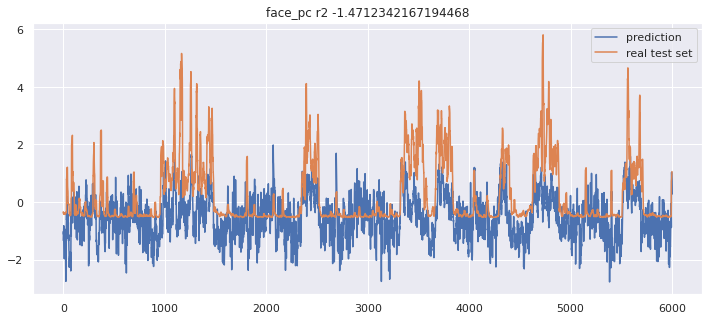

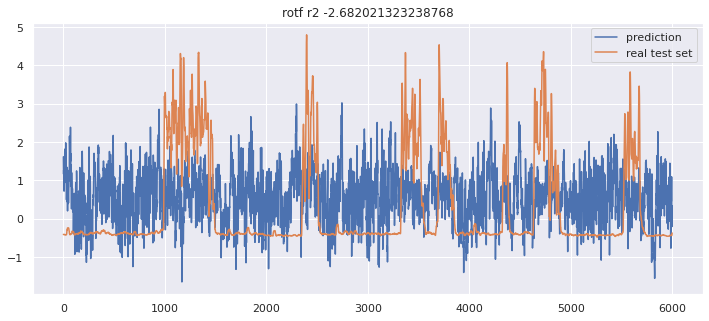

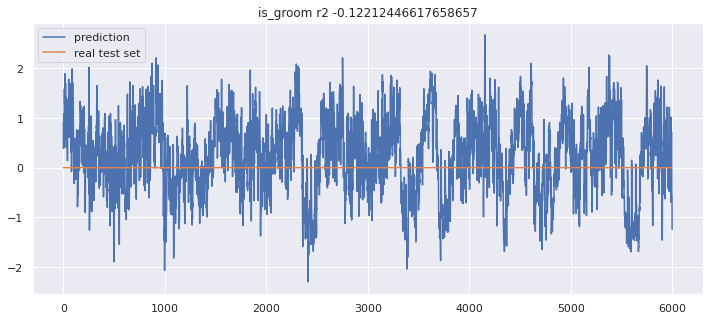

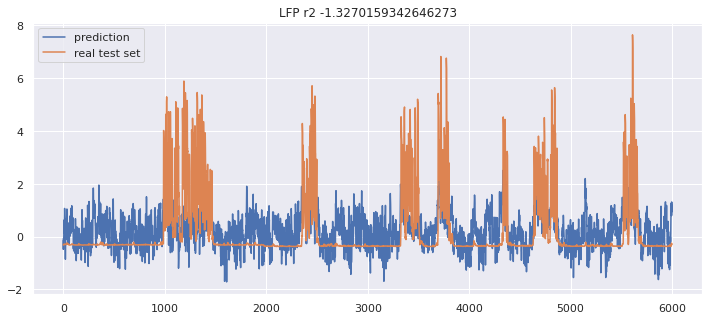

In [47]:
for i, name in enumerate(['whisk_vel', 'face_pc', 'rotf', 'is_groom', 'LFP']):
    plt.figure(figsize=(12,5))
    t_range = range(9000,15000)
    plt.plot(Y_hat_concat[t_range,i],label='prediction')
    plt.plot(Y_concat[t_range,i],label='real test set')
    r22 = r2_score(Y_hat_concat[:,i],Y_concat[:,i])
    plt.legend()
    plt.title(name+ ' r2 '+str(r22))

In [10]:
col_list = ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
col = sns.xkcd_palette(col_list)
col = sns.color_palette("Set2")+sns.color_palette("Paired")+col
col[2],col[16] =col[16],col[2]

In [11]:
mice=['cm125','cm126','cm128']
score_table = pd.DataFrame()
for mouse in mice:
    linear_score_table = pd.read_pickle('/home/wx2203/Weihao/analysis_locker/f4/'+mouse+'_linear_score_table.pickle')
    linear_score_table['model_type']='linear'
    linear_score_table['mouse']=mouse
    score_table = score_table.append(linear_score_table)
    convnet_score_table = pd.read_pickle('/home/wx2203/Weihao/analysis_locker/f4/'+mouse+'_convnet_score_table.pickle')
    convnet_score_table['model_type']='conv'
    convnet_score_table['mouse']=mouse
    score_table = score_table.append(convnet_score_table)

In [12]:
score_table.shape

(214, 4)

In [22]:
mice=['cm125','cm126','cm128']
linear_all = pd.DataFrame()
convnet_all = pd.DataFrame()
for mouse in mice:
    linear_score_table = pd.read_pickle('/home/wx2203/Weihao/analysis_locker/f4/'+mouse+'_linear_score_table.pickle')
    linear_score_table['model_type']='linear'
    linear_score_table['mouse']=mouse
    linear_all = linear_all.append(linear_score_table)
    
    convnet_score_table = pd.read_pickle('/home/wx2203/Weihao/analysis_locker/f4/'+mouse+'_convnet_score_table.pickle')
    convnet_score_table['model_type']='conv'
    convnet_score_table['mouse']=mouse
    convnet_all = convnet_all.append(convnet_score_table)
    
    print(mouse,' FACE: linear vs conv',stats.ttest_rel(linear_score_table['face_score'],convnet_score_table['face_score']))
    print(mouse,' BODY: linear vs conv',stats.ttest_rel(linear_score_table['body_score'],convnet_score_table['body_score']))




cm125  FACE: linear vs conv Ttest_relResult(statistic=-18.461894229356272, pvalue=6.2500733983210765e-18)
cm125  BODY: linear vs conv Ttest_relResult(statistic=-17.319760379440496, pvalue=3.620199476120797e-17)
cm126  FACE: linear vs conv Ttest_relResult(statistic=-14.962133275135193, pvalue=1.875137809092588e-15)
cm126  BODY: linear vs conv Ttest_relResult(statistic=-17.281083962284146, pvalue=3.8484728013453944e-17)
cm128  FACE: linear vs conv Ttest_relResult(statistic=-30.298703380919164, pvalue=4.1063393588921585e-31)
cm128  BODY: linear vs conv Ttest_relResult(statistic=-29.25784632625713, pvalue=1.7804965171966702e-30)


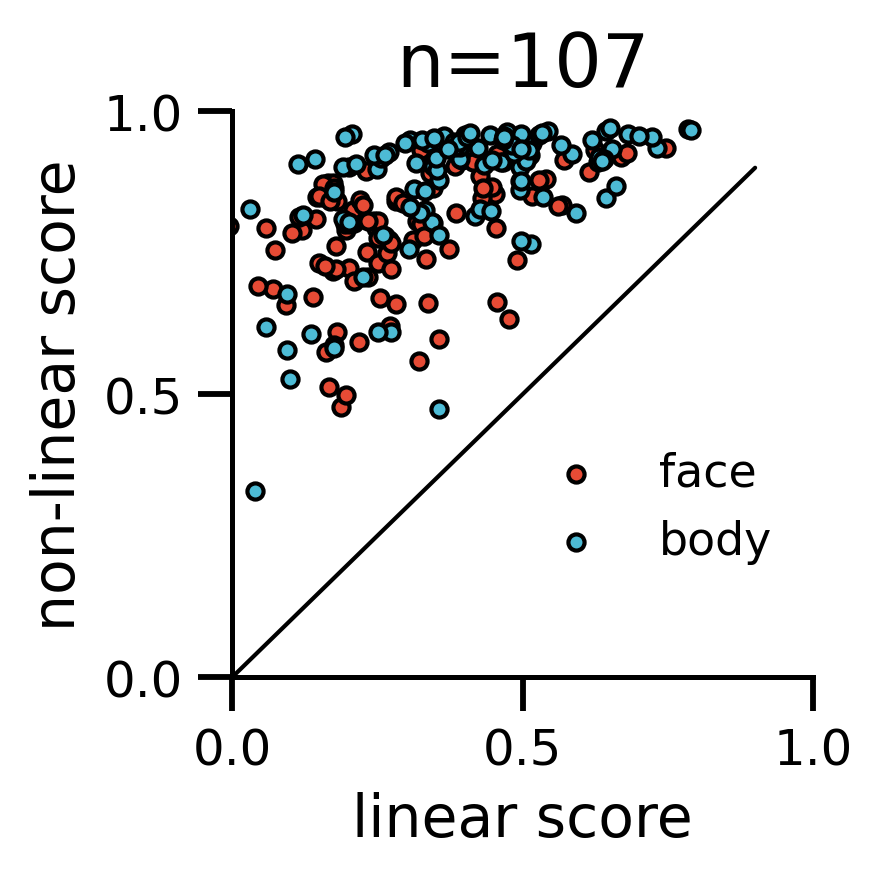

In [198]:
xx=np.arange(0,1,0.1)
with plt.style.context('default'):
    plt.figure(figsize=(2.5,2.5))

    plt.scatter(linear_all['face_score'],convnet_all['face_score'],s=15,label='face')
    plt.scatter(linear_all['body_score'],convnet_all['body_score'],s=15,label='body')
    plt.plot(xx,xx,color='black',linewidth=1)
    plt.xlim([0,1])
    plt.yticks([0,0.5,1])
    plt.xticks([0,0.5,1])
    plt.ylim([0,1])
    plt.title('n=107')
    plt.xlabel('linear score')
    plt.ylabel('non-linear score')
    plt.legend(loc='center right', bbox_to_anchor=(1, 0.3))
    
plt.savefig('/home/wx2203/Weihao/analysis_locker/f4/svgs/'+'ALL_score_scatter_plot.svg', format='svg',dpi=300)

In [156]:
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [158]:
score_table.head()

,,face_score,body_score,model_type,mouse
row_level,,,,,
cm125_1_runI,0,0.342101,0.337126,linear,cm125
cm125_1_runG,0,0.614003,0.681002,linear,cm125
cm125_1_runJ,0,0.383778,0.516967,linear,cm125
cm125_1_runE,0,0.494641,0.527610,linear,cm125
cm125_1_runC,0,0.452941,0.465381,linear,cm125


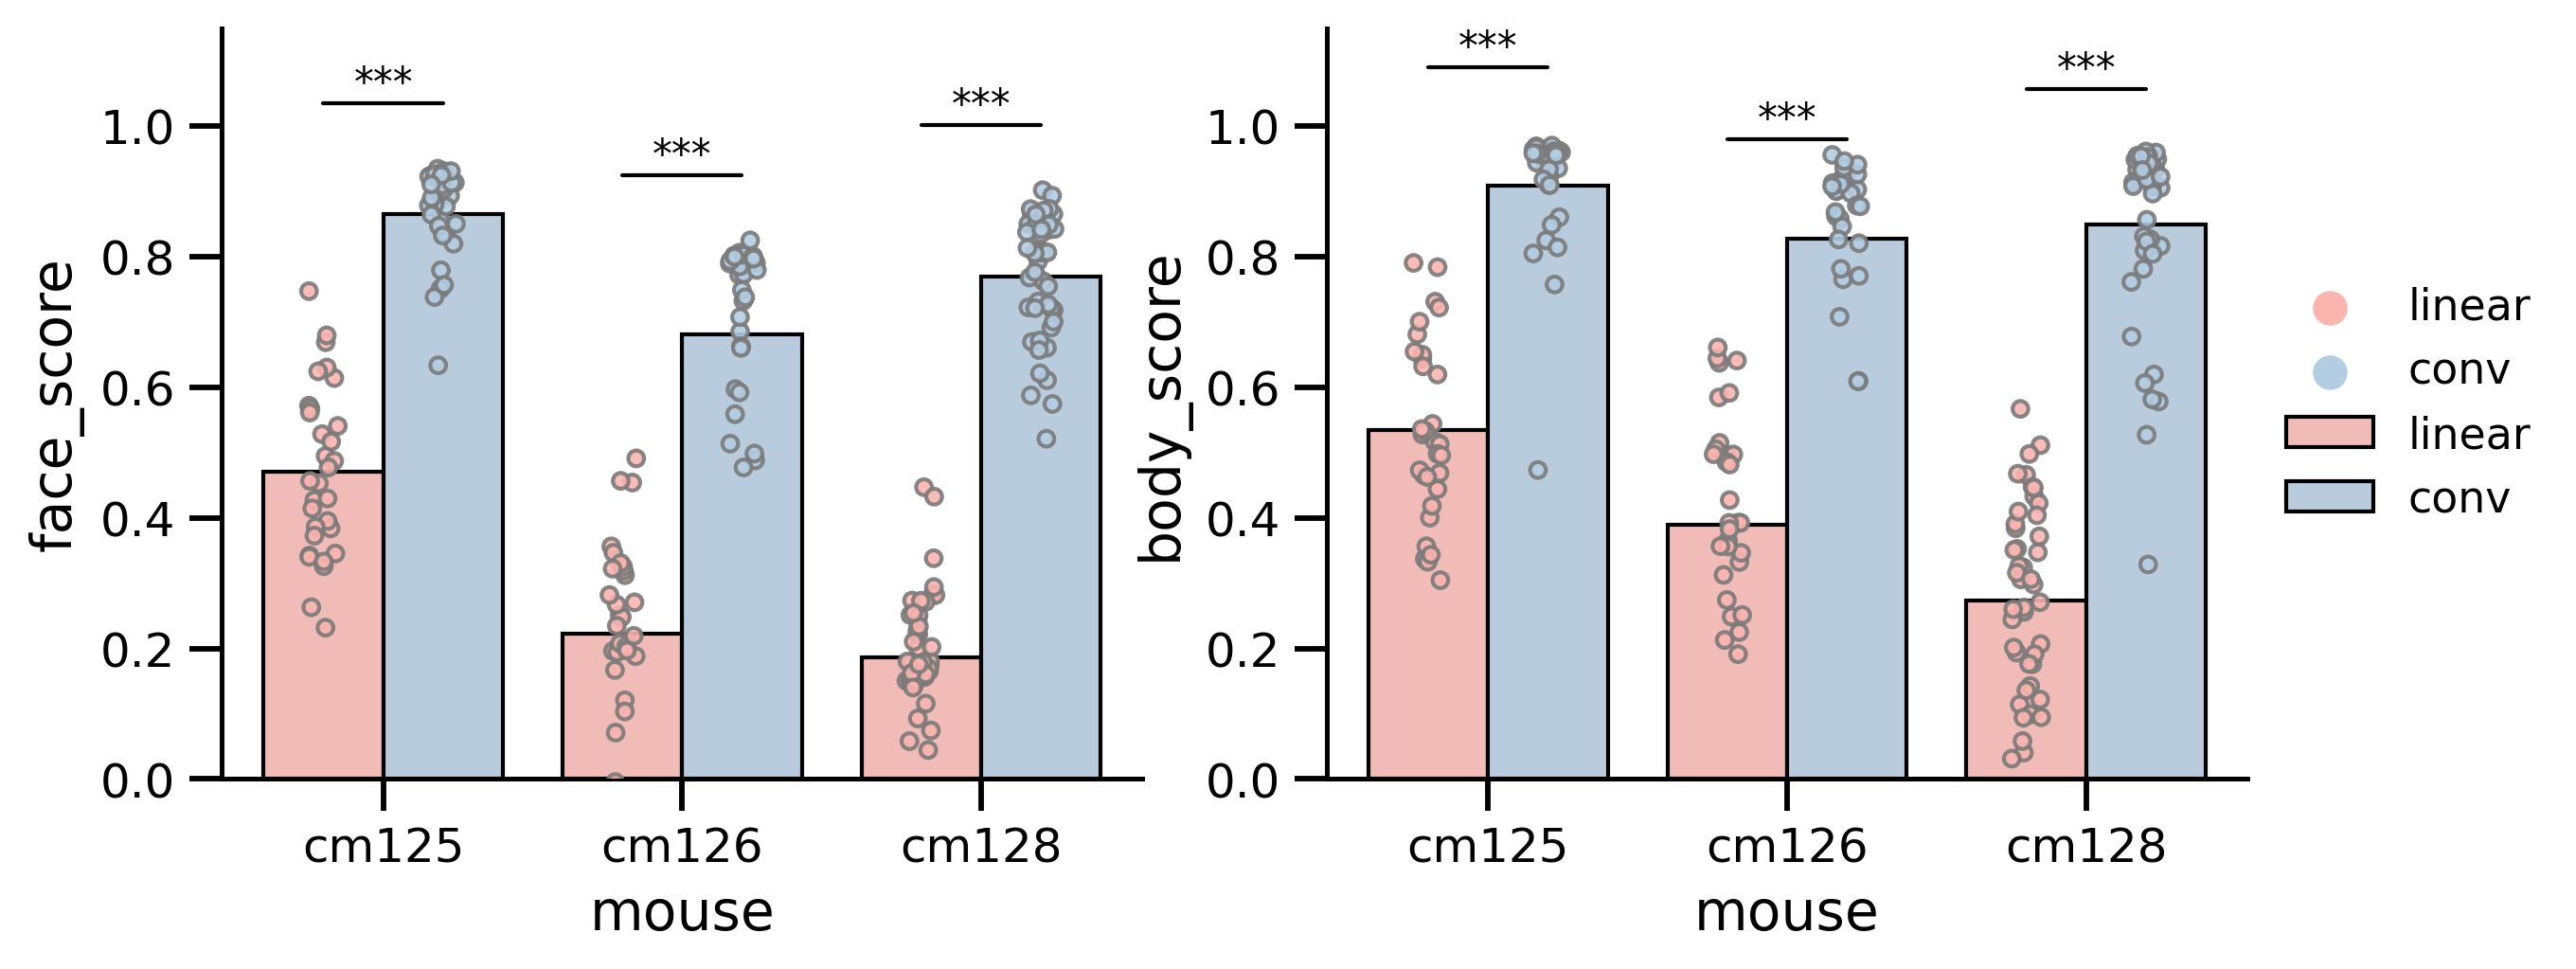

In [270]:
with plt.style.context('default'):
    plt.figure(figsize=(9.2,3.5))
    plt.subplot(121)
    sns.barplot(x="mouse", y="face_score", hue="model_type", palette="Pastel1",data=score_table,ci=None)
    sns.stripplot(x="mouse", y="face_score", hue="model_type", data=score_table,jitter=True,palette="Pastel1",linewidth=1,size=4,alpha=0.9,edgecolor='gray',dodge=True)
    
    # statistical annotation
    for i,mouse in enumerate(['cm125','cm126','cm128']):
        x1, x2 = -0.2+i, 0.2+i
        y, h, col = score_table[score_table['mouse']==mouse]['face_score'].max() + 0.1, 0.0, 'k'
        plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1, c='black')
        plt.text(i, y+h, "***", ha='center', va='bottom', color='black')

    plt.ylim([0,1.15])
    plt.legend([],[], frameon=False)
#     plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    
    plt.subplot(122)
    sns.barplot(x="mouse", y="body_score", hue="model_type", palette="Pastel1",data=score_table,ci=None)
    sns.stripplot(x="mouse", y="body_score", hue="model_type", data=score_table,jitter=True,palette="Pastel1",linewidth=1,size=4,alpha=0.9,edgecolor='gray',dodge=True)
    
    
    # statistical annotation
    for i,mouse in enumerate(['cm125','cm126','cm128']):
        x1, x2 = -0.2+i, 0.2+i
        y, h, col = score_table[score_table['mouse']==mouse]['face_score'].max() + 0.155, 0.0, 'k'
        plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1, c='black')
        plt.text(i, y+h, "***", ha='center', va='bottom', color='black')


    plt.ylim([0,1.15])
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
#     plt.legend([],[], frameon=False)
    


plt.savefig('/home/wx2203/Weihao/analysis_locker/f4/svgs/'+'ALL_score_box_plot_w_jitter.svg', format='svg',dpi=300)

In [13]:
score_table.head()

,,face_score,body_score,model_type,mouse
row_level,,,,,
cm125_1_runI,0,0.342101,0.337126,linear,cm125
cm125_1_runG,0,0.614003,0.681002,linear,cm125
cm125_1_runJ,0,0.383778,0.516967,linear,cm125
cm125_1_runE,0,0.494641,0.527610,linear,cm125
cm125_1_runC,0,0.452941,0.465381,linear,cm125


In [11]:
mouse='cm125'

In [12]:
kernel_len=21

model_weights_filename = f4_locker_root+mouse+'_kernel_len_'+str(kernel_len)+'.hdf5'
num_in_features = 153
num_out_features = 2
model = prepare_model('mean_absolute_error','accuracy',
                                    kernel_len,
                                    num_in_features,
                                    num_out_features)

model = load_model(model, model_weights_filename)


In [13]:
f = scipy.io.loadmat('/home/wx2203/Weihao/analysis_locker/f2/'+mouse+'_motor_region_ind_0_0000001.mat')
motor_region_ind = np.squeeze(f['motor_region_ind'])

In [14]:
f = scipy.io.loadmat('/home/wx2203/Weihao/analysis_locker/f2s/'+'whisk_cm125_filtered_M_0224_bouts_92.mat')
M_jrgeco=f['M_jrgeco']
ss = M_jrgeco.shape
M_jrgeco = stats.zscore(M_jrgeco.reshape((ss[0],ss[1]*ss[2])),axis=1).reshape((ss[0],ss[1],ss[2]))

M_face_pc=f['M_face_pc']
M_body_pc = f['M_body_pc']

M_jrgeco = M_jrgeco[motor_region_ind==1,:,:]
M_jrgeco = M_jrgeco.transpose((1,2,0))

print(M_jrgeco.shape,M_face_pc.shape,M_body_pc.shape)

(200, 92, 153) (200, 92) (200, 92)


In [15]:
time_length = 127
i=40
X = M_jrgeco[i:i+time_length,:,:]
face_pc=M_face_pc[i:i+time_length,:]
body_pc=M_body_pc[i:i+time_length,:]
Y = np.concatenate((face_pc[:,:,np.newaxis],body_pc[:,:,np.newaxis]),axis=-1)

data_gen = TimeseriesGenerator(X,Y,length=kernel_len,stride = kernel_len,sampling_rate=1,
                            batch_size=1000000) 
XX , YY = data_gen[0]
ss = XX.shape
XX = XX.transpose((0,2,1,3)).reshape((ss[0]*ss[2],ss[1],-1))
YY = YY.reshape((ss[0]*ss[1],ss[2],-1))

YY_predict = model.predict(XX)
YY_predict = YY_predict.reshape((ss[0],ss[2],ss[1],-1)).transpose((0,2,1,3)).reshape((ss[0]*ss[1],ss[2],-1))

    

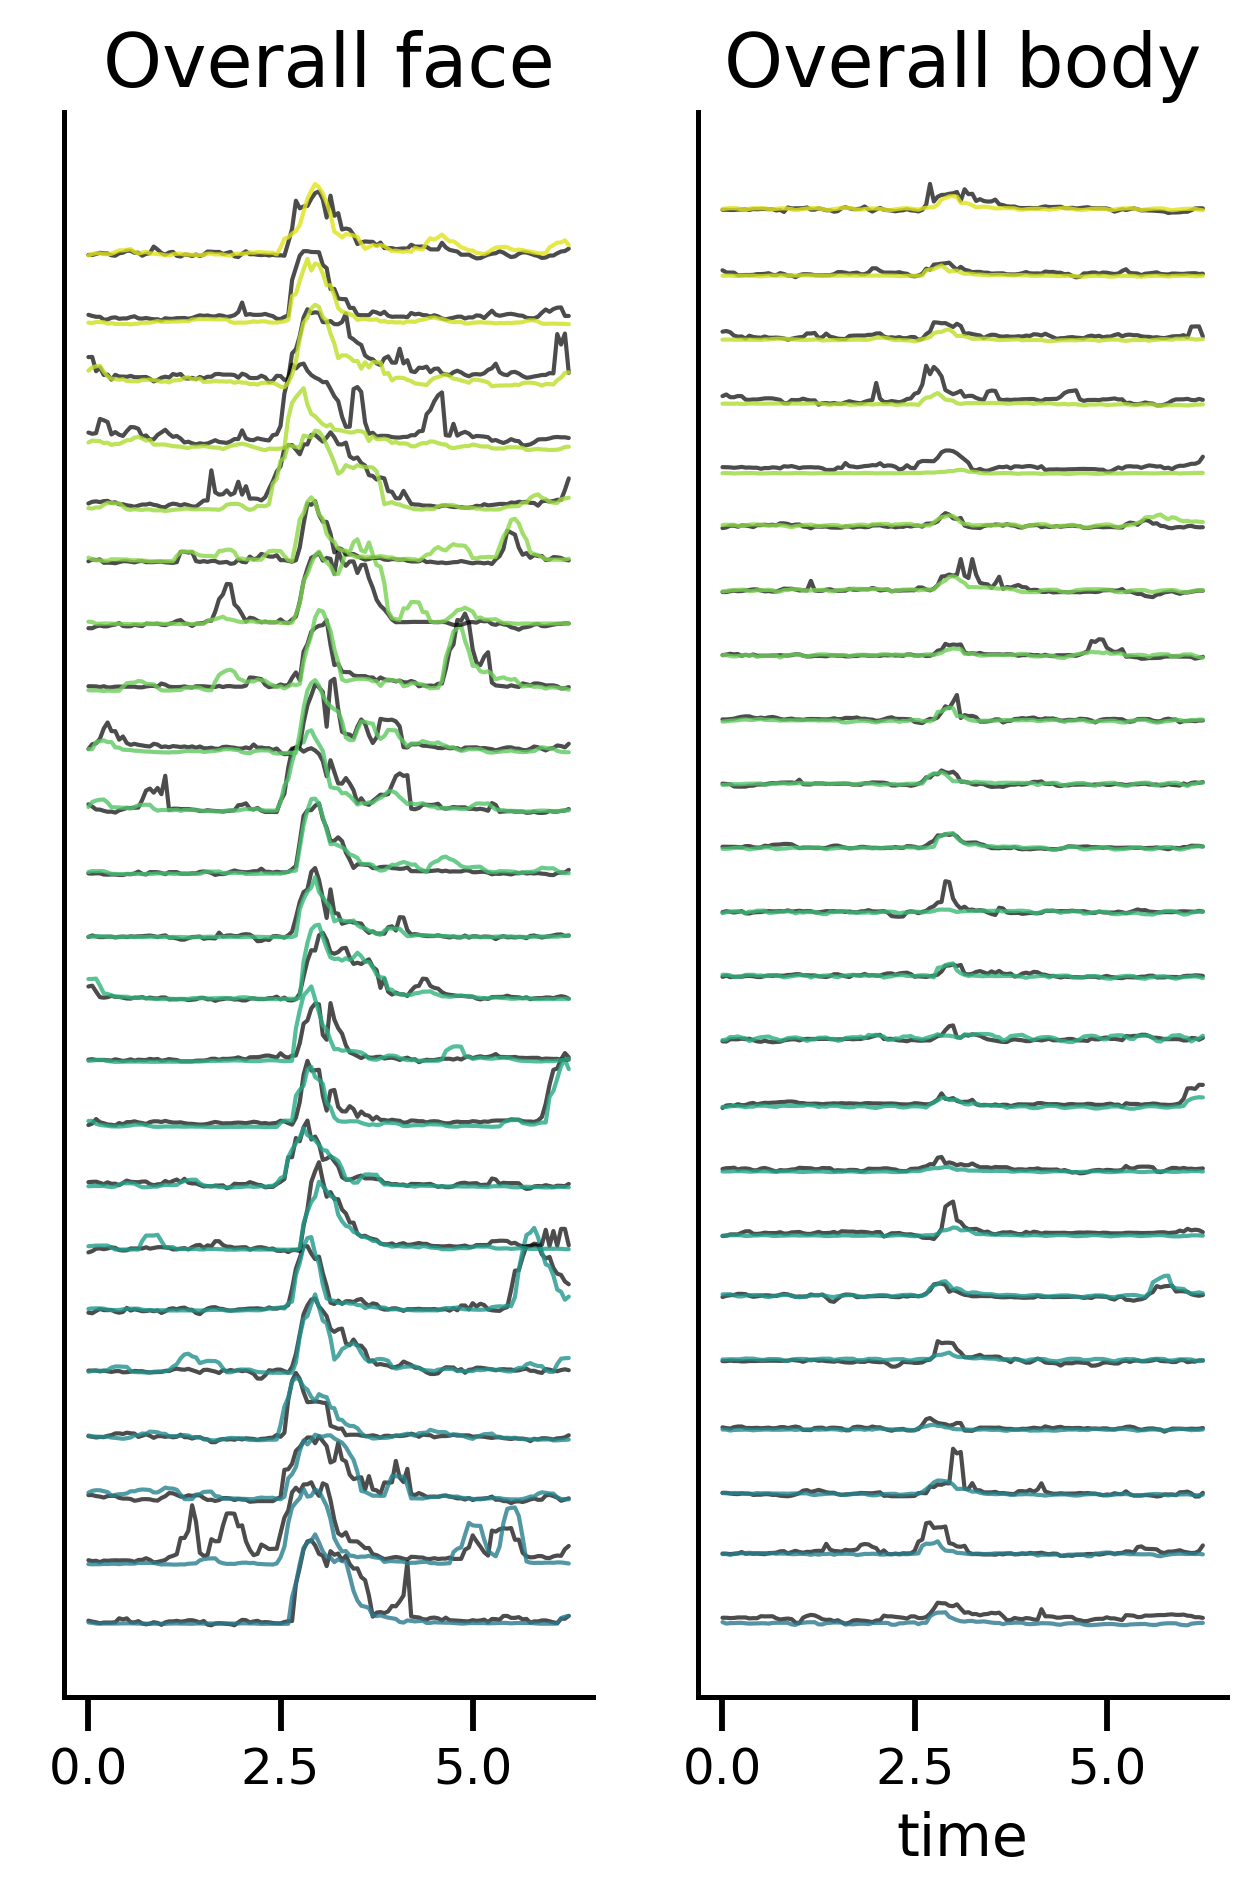

In [200]:
my_xticks = np.divide(range(YY_predict.shape[0]),20)

with plt.style.context('default'):
    plt.figure(figsize=(5,7))
    plt.subplot(121)
    off_set = 0.5
    cc = sns.color_palette("viridis",n_colors=len(plot_range)+16)
    plot_range = range(0,92,4)
    for i_c,i in enumerate(plot_range):
        plt.plot(my_xticks,YY_predict[:,i,0]+i*off_set, color='black',alpha=0.7,linewidth=1)
        plt.plot(my_xticks,YY[:,i,0]+i*off_set,linewidth=1,color=cc[i_c+15],alpha=0.8)
        plt.yticks([])
        plt.title('Overall face')
#         plt.xticks(np.array(x[::20],dtype='int'), 
#                np.array(my_xticks[::20],dtype='int'));

    plt.subplot(122)
    for i_c,i in enumerate(plot_range):
        plt.plot(my_xticks,YY_predict[:,i,1]+i*off_set, color='black',alpha=0.7,linewidth=1)
        plt.plot(my_xticks,YY[:,i,1]+i*off_set,linewidth=1,color=cc[i_c+15],alpha=0.8)
        plt.yticks([])
        plt.title('Overall body')
#         plt.xticks(np.array(x[::20],dtype='int'), 
#                np.array(my_xticks[::20],dtype='int'));

    plt.xlabel('time')
plt.savefig('/home/wx2203/Weihao/analysis_locker/f4/svgs/'+mouse+'_convnet_pred.svg', format='svg',dpi=300)

# Linear

In [25]:
face_motorLassoModel = load_pickle(f4_locker_root+mouse+'_face_motorLassoModel')
body_motorLassoModel = load_pickle(f4_locker_root+mouse+'_body_motorLassoModel')

In [39]:
time_length = 127
i=40
X = M_jrgeco[i:i+time_length,:,:]
face_pc=M_face_pc[i:i+time_length,:]
body_pc=M_body_pc[i:i+time_length,:]
ss=X.shape
X = X.reshape((ss[0]*ss[1],-1))

# Y = np.concatenate((face_pc[:,:,np.newaxis],body_pc[:,:,np.newaxis]),axis=-1)

# data_gen = TimeseriesGenerator(X,Y,length=kernel_len,stride = kernel_len,sampling_rate=1,
#                             batch_size=1000000) 
# XX , YY = data_gen[0]
# ss = XX.shape
# XX = XX.transpose((0,2,1,3)).reshape((ss[0]*ss[2],ss[1],-1))
# YY = YY.reshape((ss[0]*ss[1],ss[2],-1))

face_predict = face_motorLassoModel.predict(X).reshape((ss[0],ss[1]))
body_predict = body_motorLassoModel.predict(X).reshape((ss[0],ss[1]))
# YY_predict = YY_predict.reshape((ss[0],ss[2],ss[1],-1)).transpose((0,2,1,3)).reshape((ss[0]*ss[1],ss[2],-1))



In [74]:
cc = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488',
                  '#F39B7F', '#8491B4', '#91D1C2FF', '#DC0000',
                  '#7E6148', '#B09C85','#6794a7', '#014d64', '#7ad2f6', '#01a2d9',
                  '#7bc0c1', '#00887d', '#91D1C2FF', '#DC0000',
                  '#7E6148', '#B09C85','#3B4992FF', '#EE0000FF', '#008B45FF',
                  '#631879FF', '#008280FF', '#BB0021FF',
                  '#5F559BFF', '#A20056FF', '#808180FF',
                  '#1B1919FF',"#DD271C", '#015A9C', '#EBDC75', '#071C13', '#E5E3E4']
cc=['#6794a7', '#014d64', '#7ad2f6', '#01a2d9',
                  '#7bc0c1', '#00887d', '#91D1C2FF', '#DC0000',
                  '#7E6148', '#B09C85','#B09C85','#B09C85','#B09C85','#B09C85','#B09C85',
   '#B09C85','#B09C85','#B09C85','#B09C85',
   '#B09C85','#B09C85','#B09C85','#B09C85',
   '#B09C85','#B09C85','#B09C85','#B09C85',
   '#B09C85','#B09C85','#B09C85','#B09C85']

In [89]:
a=sns.color_palette("icefire",n_colors=30)

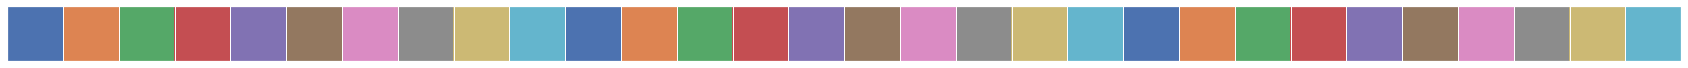

In [93]:
sns.palplot(sns.color_palette("deep", 30))

In [91]:
len(plot_range)

23

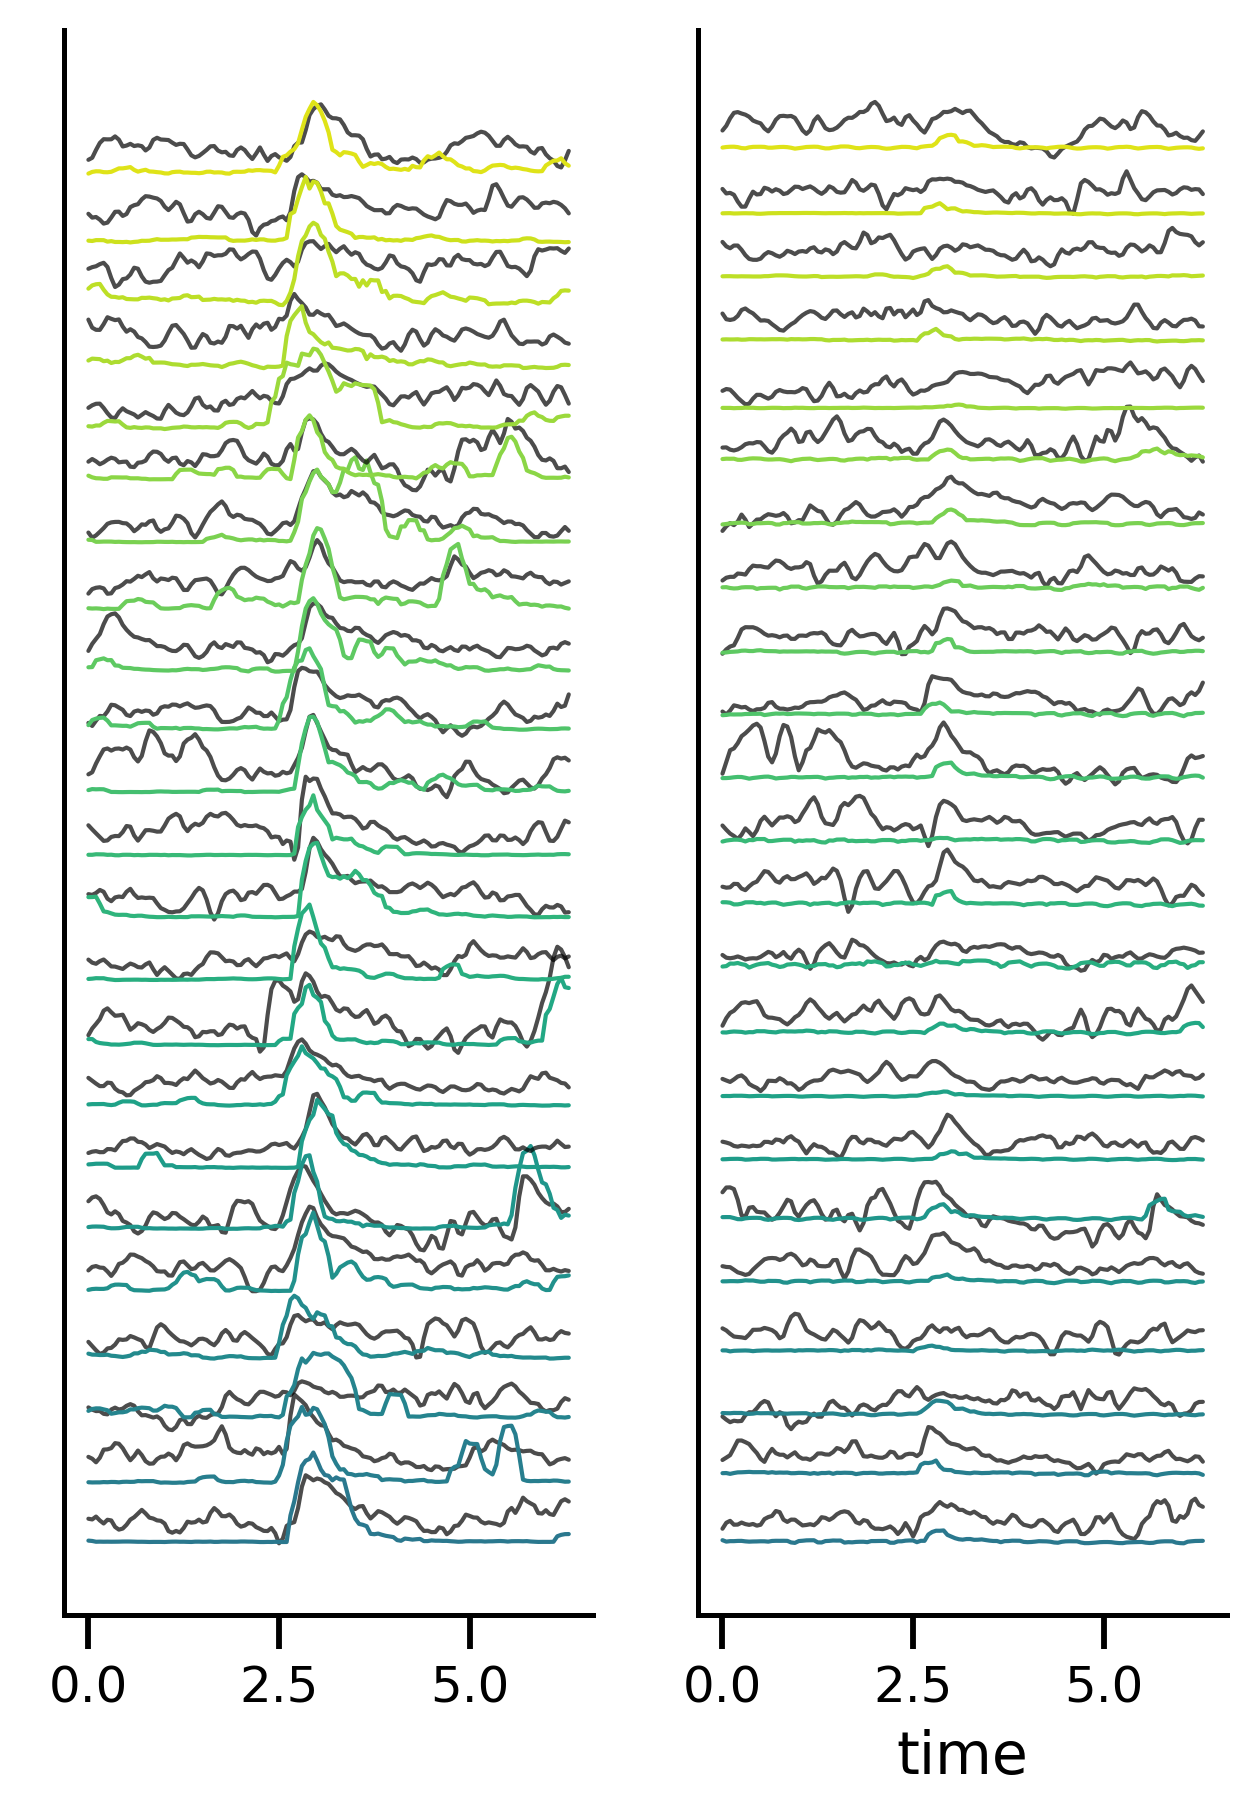

In [201]:
my_xticks = np.divide(range(face_predict.shape[0]),20)
with plt.style.context('default'):
    
    plt.figure(figsize=(5,7))
    plt.subplot(121)
    off_set = 0.5
    plot_range = range(0,92,4)
    cc = sns.color_palette("viridis",n_colors=len(plot_range)+16)
    for i_c,i in enumerate(plot_range):
        plt.plot(my_xticks,face_predict[:,i]+i*off_set, color='black',alpha=0.7,linewidth=1)
        plt.plot(my_xticks,face_pc[:,i]+i*off_set,linewidth=1,color=cc[i_c+15])
        plt.yticks([])

    plt.subplot(122)
    for i_c,i in enumerate(plot_range):
        plt.plot(my_xticks,body_predict[:,i]+i*off_set, color='black',alpha=0.7,linewidth=1)
        plt.plot(my_xticks,body_pc[:,i]+i*off_set,linewidth=1,color=cc[i_c+15])
        plt.yticks([])


    plt.xlabel('time')
plt.savefig('/home/wx2203/Weihao/analysis_locker/f4/svgs/'+mouse+'_linear_pred.svg', format='svg',dpi=300)